#**ANÁLISIS ESTADÍSTICO DE TIROTEOS EN ESTADOS UNIDOS**

**Universidad Industrial de Santander**

**Escuela de Ingeniería de Sistemas**

**IA**






Realizado por:

*   Jean Carlo Rodríguez Pico - 2214116
*   Juan Pablo Ávila Quitián - 2214107
*   Juan David Saavedra Gonzalez - 2214111

Ejecute la siguiente celda de código para no presentar fallos al momento de ejecutar o revisar la actividad.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


## **Tiroteos en Estados Unidos**

El presente proyecto se abarca un análisis estadístico descriptivo e inferencial sobre los tiroteos ocurridos en Estados Unidos. Con este fin, se utilizó un conjunto de datos que contiene información detallada sobre los incidentes de tiroteos, incluyendo variables como la fecha, ubicación, número de víctimas, entre otros. Esto con el objetivo de aplicar diferentes temas vistos en la asignatura durante el semeste académico en un contexto real y de relevancia social.

A continuación, se secciona el conjunto de datos utilizado, junto con algunos datos indexados y utilizados más adelante.

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ProyectoIA/TiroteosUSA.csv", sep=',')
df

NameError: name 'pd' is not defined

Por conveniencia del proyecto y facilidad en el tratamiento de los datos, es necesario realizar algunos recortes al conjunto de datos, quitando algunas variables que no son de importancia para el estudio.

In [ ]:
columns_to_drop = ['S#', 'Unnamed: 0', 'Incident Area','Cause','Employed at','Summary']
df.drop(columns=columns_to_drop, axis=1, inplace=True)

In [ ]:
df['Employeed (Y/N)'] = df['Employeed (Y/N)'].fillna(0.0)
df['Policeman Killed'] = df['Policeman Killed'].fillna(0.0)
df['Age'] = df['Age'].fillna(0.0)

Una vez descartadas las variables prescindibles, se muestra enseguida las variables que se atenderán y harán parte de todo el proceso de estudio.

In [ ]:
df.columns

Index(['Title', 'Location', 'Date', 'Open/Close Location', 'Target',
       'Fatalities', 'Injured', 'Total victims', 'Policeman Killed', 'Age',
       'Employeed (Y/N)', 'Mental Health Issues', 'Race', 'Gender', 'Latitude',
       'Longitude'],
      dtype='object')

In [ ]:
# Eliminar filas que tengan cualquier NaN
df.dropna(inplace=True)


In [ ]:
df

,Title,Location,Date,Open/Close Location,Target,Fatalities,Injured,Total victims,Policeman Killed,Age,Employeed (Y/N),Mental Health Issues,Race,Gender,Latitude,Longitude
11,"Ferguson, MO Drive by","Ferguson, Missouri",4/29/2016,Open,random,0,4,4,0.0,0,0.0,Unknown,Unknown,Unknown,38.744217,-90.305391
23,"Richmond, Virginia","Richmond, Virginia",3/31/2016,Open,Trooper,2,2,3,0.0,0.0,0.0,Unknown,Black American or African American,Male,37.540725,-77.436048
25,"Lawrenceburg, Tennessee","Lawrenceburg, Tennessee",3/25/2016,Close,Family,2,2,3,0.0,0.0,0.0,Unknown,Unknown,Male,35.242302,-87.334739
28,"Louisville, KY Family Murder-Suicide","Louisville, Kentucky",3/20/2016,Close,Family,4,0,3,0.0,0.0,1.0,Yes,White American or European American,Male,38.252665,-85.758456
29,"Plantation, Florida","Plantation, Florida",3/19/2016,Close,party guests,1,4,5,0.0,0.0,0.0,Unknown,Unknown,Unknown,26.127586,-80.233104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
957,Olean High School,"Olean, New York",12/30/1974,Open+Close,random,3,7,10,0.0,17,0.0,No,White American or European American,Male,42.081854,-78.432139
958,Clara Barton Elementary School,"Chicago, Illinois",1/17/1974,Close,Teachers,1,3,4,0.0,14,0.0,Yes,Unknown,Male,41.839280,-87.688181
960,St. Aloysius Church,"Spokane, Washington",11/11/1971,Close,random,2,4,5,0.0,0.0,0.0,Yes,White American or European American,Male,47.673674,-117.415984
961,Rose-Mar College of Beauty,"Mesa, Arizona",11/12/1966,Close,random,5,1,6,0.0,18,0.0,Yes,White American or European American,Male,33.422687,-111.816320


Al observar y enumerar las columnas del conjunto de datos, se obtienen exactamente 18, que harán parte de las variables de estudio. A su vez, este contiene 963 registros formando así en total 17334 datos, contando aquellos con valores nulos.

In [ ]:
df.shape

(691, 16)

Por último, es necesario cambiar el tipo de dato y su valor para algunas variables, permitiendo un mejor manejo y uniforamar estos datos tanto de forma cuantitativa como cualitativa para utilidad del proyecto.

In [ ]:
# Reemplazar valores en la columna 'Mental Health Issues'
df['Mental Health Issues'] = df['Mental Health Issues'].replace(['Unknown', 'unknown'], 'Unclear')

In [ ]:
# Reemplazar valores en la columna 'Gender'
df['Gender'] = df['Gender'].replace(['M', 'Unknown', 'Male/Female', 'M/F'], 'Unclear')
df['Gender'] = df['Gender'].replace('M', 'Male')

In [ ]:
# Reemplazar valores específicos en la columna 'Race'
df.loc[df['Race'] == 'Unknown', 'Race'] = 'Other'
df.loc[df['Race'] == 'white', 'Race'] = 'White'
df.loc[df['Race'] == 'black', 'Race'] = 'Black'

In [ ]:
# Limpiar y convertir la columna 'Age' a numérico
# Reemplaza comas por puntos y convierte a numérico
df['Age'] = df['Age'].astype(str).str.replace(',', '.').astype(float)

# Opcional: Eliminar filas con valores NaN en 'Age' si hay alguna
df = df.dropna(subset=['Age'])

Una vez realizados los cambios pertinentes al conjunto de datos, a continuación se realizan algunas técnicas empleadas en lo que va del semestre como teoría en la materia. Para ello, se realiza un análisis descriptivo de los datos para identificar patrones generales y características clave de los tiroteos, tales como su frecuencia y distribución geográfica. Luego, se lleva a cabo pruebas de hipótesis para determinar si existen diferencias significativas en la incidencia de tiroteos entre distintos estados y períodos de tiempo.

In [ ]:
df

,Title,Location,Date,Open/Close Location,Target,Fatalities,Injured,Total victims,Policeman Killed,Age,Employeed (Y/N),Mental Health Issues,Race,Gender,Latitude,Longitude
11,"Ferguson, MO Drive by","Ferguson, Missouri",4/29/2016,Open,random,0,4,4,0.0,0.0,0.0,Unclear,Other,Unclear,38.744217,-90.305391
23,"Richmond, Virginia","Richmond, Virginia",3/31/2016,Open,Trooper,2,2,3,0.0,0.0,0.0,Unclear,Black American or African American,Male,37.540725,-77.436048
25,"Lawrenceburg, Tennessee","Lawrenceburg, Tennessee",3/25/2016,Close,Family,2,2,3,0.0,0.0,0.0,Unclear,Other,Male,35.242302,-87.334739
28,"Louisville, KY Family Murder-Suicide","Louisville, Kentucky",3/20/2016,Close,Family,4,0,3,0.0,0.0,1.0,Yes,White American or European American,Male,38.252665,-85.758456
29,"Plantation, Florida","Plantation, Florida",3/19/2016,Close,party guests,1,4,5,0.0,0.0,0.0,Unclear,Other,Unclear,26.127586,-80.233104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
957,Olean High School,"Olean, New York",12/30/1974,Open+Close,random,3,7,10,0.0,17.0,0.0,No,White American or European American,Male,42.081854,-78.432139
958,Clara Barton Elementary School,"Chicago, Illinois",1/17/1974,Close,Teachers,1,3,4,0.0,14.0,0.0,Yes,Other,Male,41.839280,-87.688181
960,St. Aloysius Church,"Spokane, Washington",11/11/1971,Close,random,2,4,5,0.0,0.0,0.0,Yes,White American or European American,Male,47.673674,-117.415984
961,Rose-Mar College of Beauty,"Mesa, Arizona",11/12/1966,Close,random,5,1,6,0.0,18.0,0.0,Yes,White American or European American,Male,33.422687,-111.816320


In [ ]:
df.describe()

,Date,Fatalities,Injured,Total victims,Policeman Killed,Age,Employeed (Y/N),Latitude,Longitude
count,688,688.000000,688.000000,688.000000,688.000000,688.000000,688.000000,688.000000,688.000000
mean,2005-08-04 04:44:39.069767424,4.585756,5.383721,9.553779,0.097384,20.095916,0.135174,37.744443,-95.113756
min,1966-08-01 00:00:00,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,21.325512,-161.792752
25%,1997-09-15 00:00:00,2.000000,1.000000,4.000000,0.000000,0.000000,0.000000,33.571459,-111.940296
50%,2011-01-08 00:00:00,4.000000,3.000000,6.000000,0.000000,19.000000,0.000000,37.383443,-88.138300
75%,2015-02-26 06:00:00,6.000000,5.000000,9.250000,0.000000,36.000000,0.000000,41.876171,-81.680515
max,2017-10-01 00:00:00,59.000000,527.000000,585.000000,4.000000,70.000000,1.000000,60.790539,-69.707823
std,NaN,4.786100,21.125765,23.860463,0.503951,18.673511,0.342159,5.611530,17.153303


## **Análisis de Gráficos**

##  Número de Tiroteos por Año

Este gráfico ilustra la tendencia en el número de tiroteos en EE.UU. a lo largo de los años. Muestra cómo ha variado la frecuencia de los tiroteos, permitiendo identificar aumentos o disminuciones en su ocurrencia.

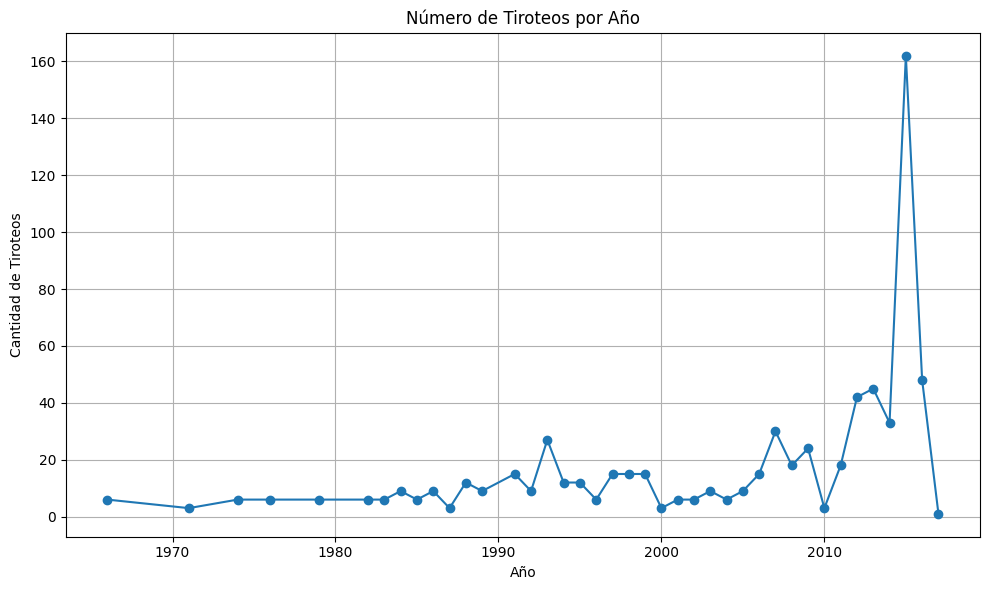

In [ ]:
# Convertir la columna 'Date' a formato de fecha
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extraer el año de la columna 'Date'
df['Year'] = df['Date'].dt.year

# Contar el número de tiroteos por año
tiroteos_por_año = df['Year'].value_counts().sort_index()

# Graficar la serie de tiempo del número de tiroteos por año
plt.figure(figsize=(10, 6))
tiroteos_por_año.plot(kind='line', marker='o')
plt.title('Número de Tiroteos por Año')
plt.xlabel('Año')
plt.ylabel('Cantidad de Tiroteos')
plt.grid(True)
plt.tight_layout()
plt.show()

# Eliminar la columna 'Year' si no es necesaria después de la gráfica
df.drop(columns=['Year'], inplace=True)


## Número de Tiroteos por Estado en EE.UU.

Este gráfico muestra la cantidad de tiroteos registrados en cada estado de EE.UU. Comparando los estados, se puede ver dónde se han producido más incidentes.

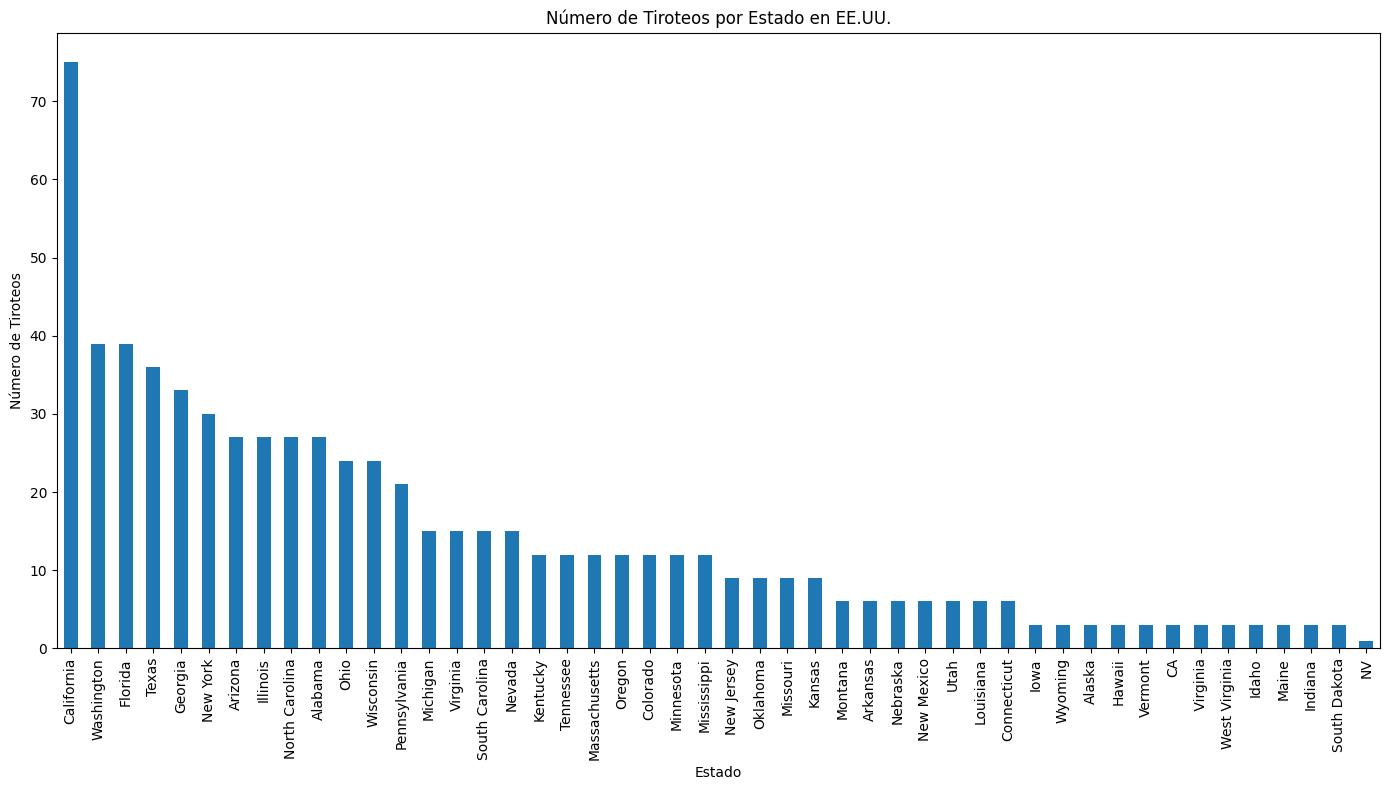

<ipython-input-15-3aa683203540>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['State'], inplace=True)


In [ ]:

df.loc[:, 'Location'] = df['Location'].fillna('Unknown')

df.loc[:, 'State'] = df['Location'].apply(lambda x: x.split(', ')[-1] if ', ' in x else 'Unknown')

df = df[df['State'] != 'Unknown']

tiroteos_por_estado = df['State'].value_counts()

plt.figure(figsize=(14, 8))
tiroteos_por_estado.plot(kind='bar')
plt.title('Número de Tiroteos por Estado en EE.UU.')
plt.xlabel('Estado')
plt.ylabel('Número de Tiroteos')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


df.drop(columns=['State'], inplace=True)


## Proporción de Empleados entre los Perpetradores

Este gráfico de pastel muestra la proporción de perpetradores de tiroteos que estaban empleados vs. los que no lo estaban. La visualización ayuda a entender la representación de empleados entre los perpetradores en relación con el total.

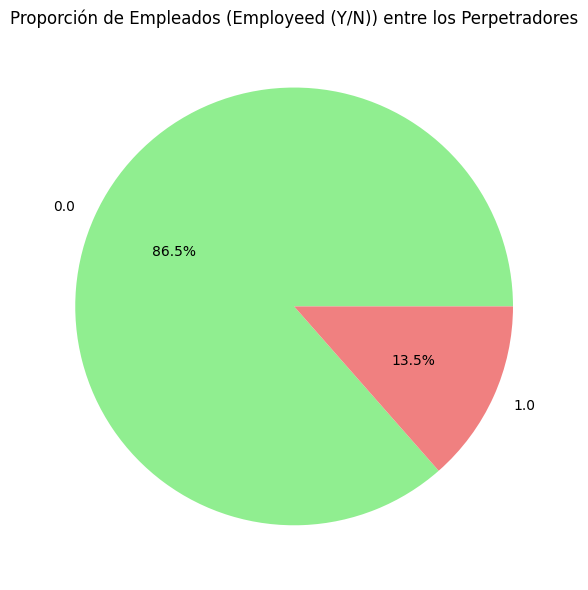

In [ ]:
# Contar el número de tiroteos por estado de empleo ('Employeed (Y/N)')
empleo_counts = df['Employeed (Y/N)'].value_counts()

# Graficar la proporción de empleados entre los perpetradores en un gráfico de pastel
plt.figure(figsize=(6, 6))
plt.pie(empleo_counts, labels=empleo_counts.index, autopct='%1.1f%%', colors=['lightgreen', 'lightcoral'])
plt.title('Proporción de Empleados (Employeed (Y/N)) entre los Perpetradores')
plt.tight_layout()
plt.show()

## Distribución de Tiroteos por Raza de los Perpetradores

Este gráfico de barras muestra la distribución de los tiroteos según la raza de los perpetradores. Representa cuántos tiroteos han sido cometidos por individuos de cada grupo racial, ayudando a visualizar la proporción de incidentes asociados a diferentes razas.

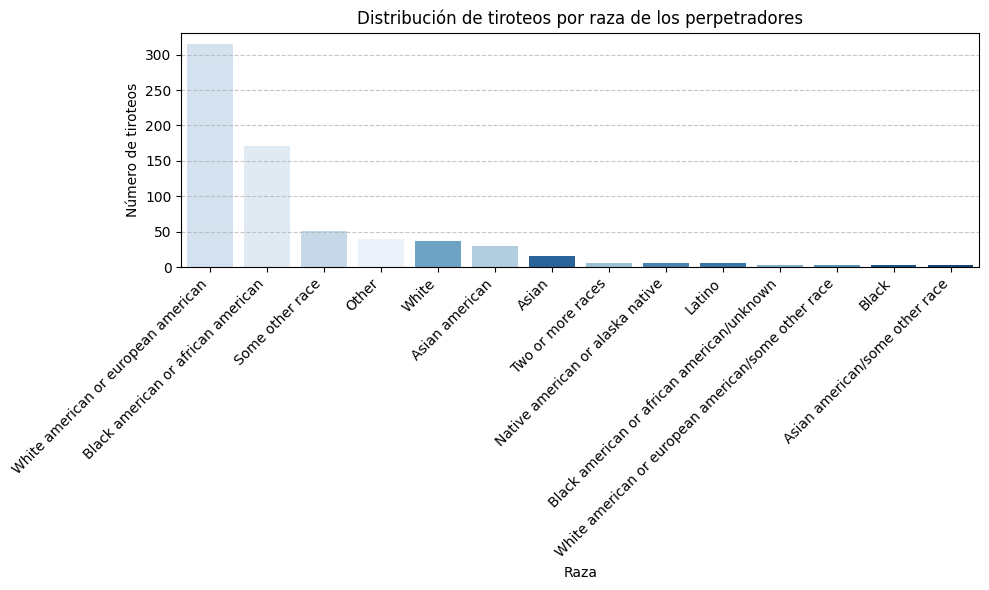

In [ ]:
import pandas as pd


# Normalizar los valores en la columna 'Race' usando .loc
df.loc[:, 'Race'] = df['Race'].str.lower().str.capitalize()

# Crear el gráfico de barras con seaborn
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Race', order=df['Race'].value_counts().index, hue='Race', palette='Blues', dodge=False, legend=False)
plt.title('Distribución de tiroteos por raza de los perpetradores')
plt.xlabel('Raza')
plt.ylabel('Número de tiroteos')
plt.xticks(rotation=45, ha='right')  # Ajustar la alineación de las etiquetas
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()  # Ajustar el layout para evitar que las etiquetas se corten
plt.show()



## Grafica de correlación

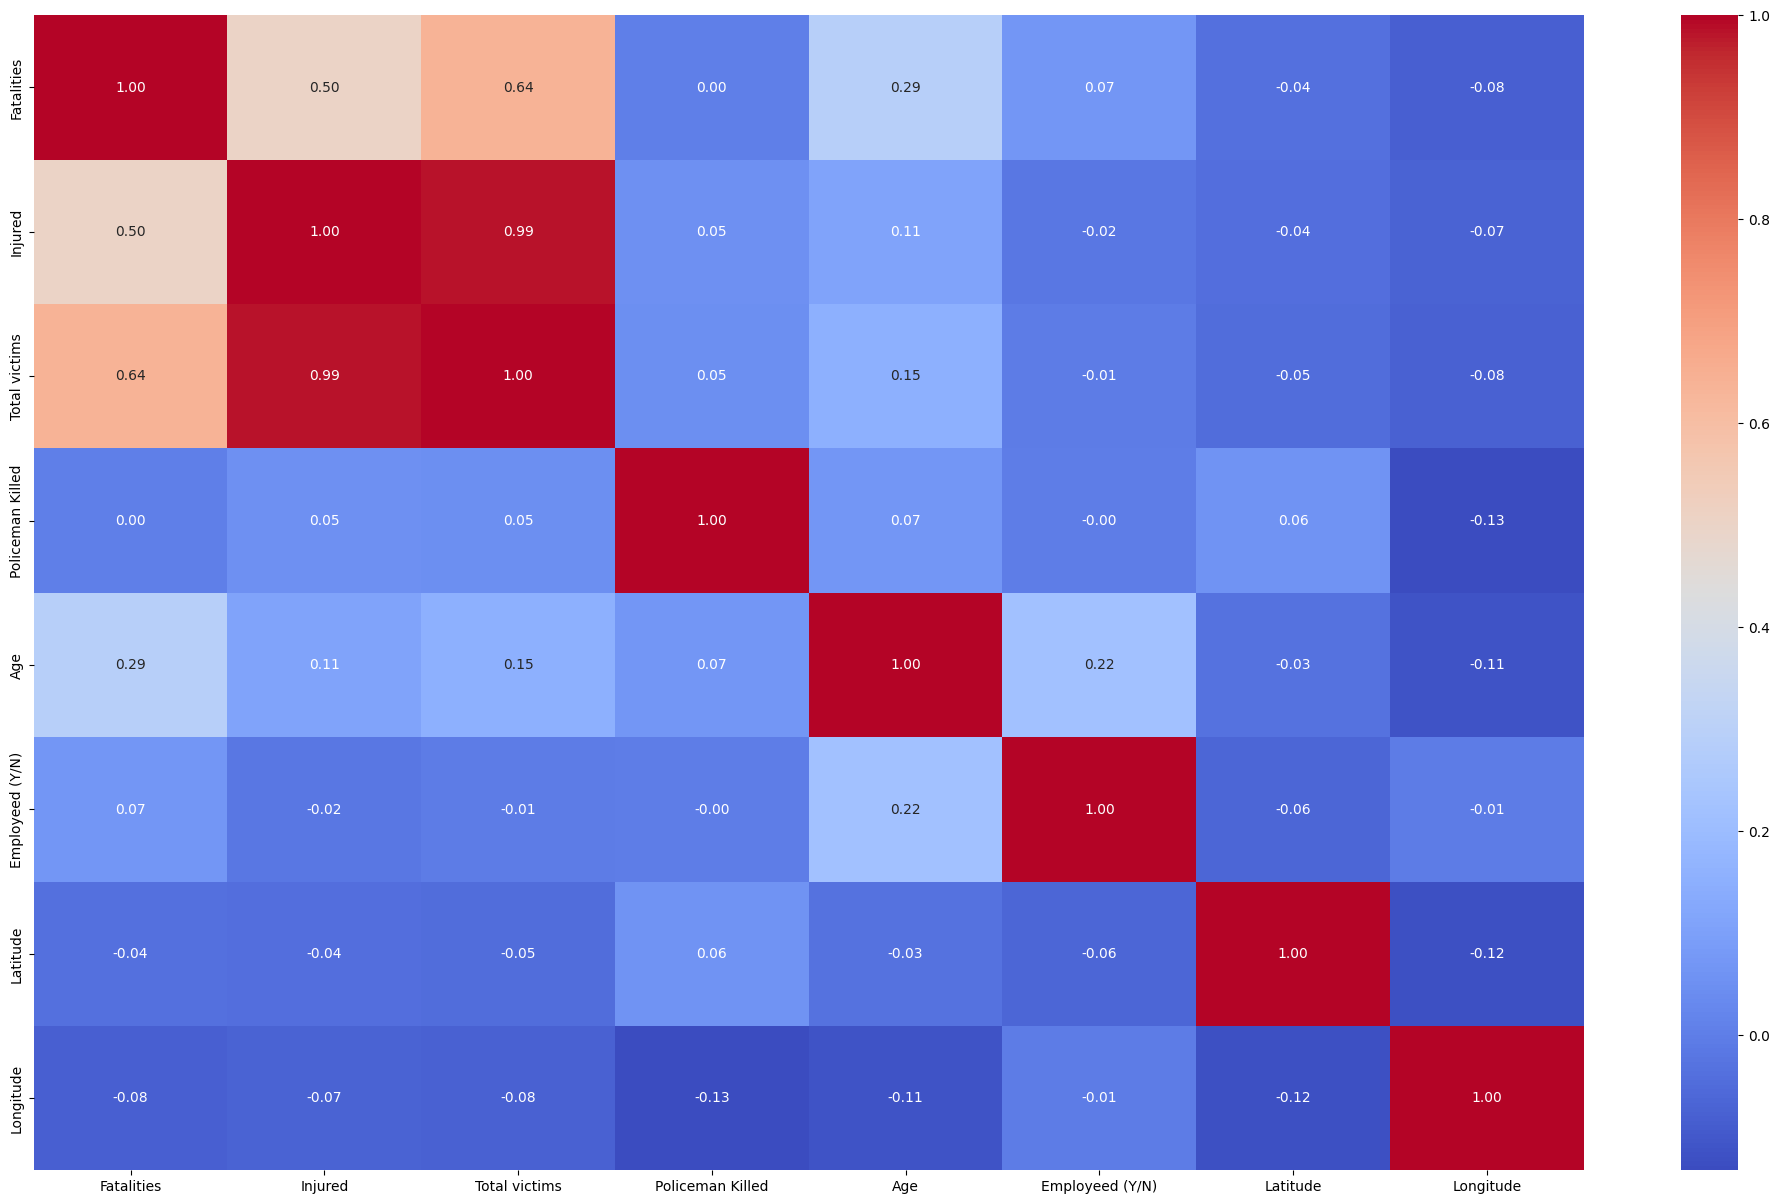

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Seleccionar solo columnas numéricas
df_numeric = df.select_dtypes(include=['float64', 'int64'])

corr = df_numeric.corr()

# Graficar el mapa de calor
plt.subplots(figsize=(25,15))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')

# Mostrar la gráfica
plt.show()


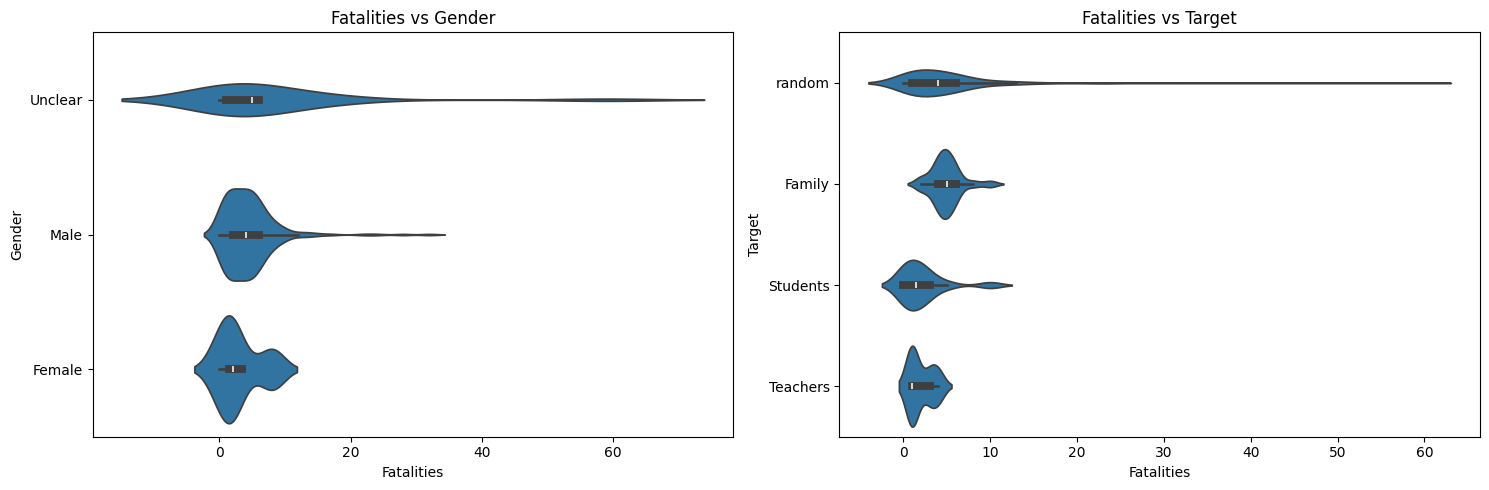

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

valores_permitidos = ["random", "Family", "Teachers", "Students"]
df_filtrado = df[df['Target'].isin(valores_permitidos)]


plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.violinplot(x="Fatalities", y="Gender", data=df)
plt.title('Fatalities vs Gender')
plt.subplot(1, 2, 2)
sns.violinplot(x="Fatalities", y="Target", data=df_filtrado)
plt.title('Fatalities vs Target')

plt.tight_layout()
plt.show()


## Proporción de Tiroteos por Tipo de Objetivo

Este gráfico de barras muestra la distribución de tiroteos según el tipo de objetivo. Indica cuántos tiroteos se dirigieron a cada tipo de objetivo, proporcionando una visión clara de las categorías más comunes y su frecuencia en el conjunto de datos.

<ipython-input-21-827ec6690577>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Target', order=df['Target'].value_counts().index, palette='viridis')


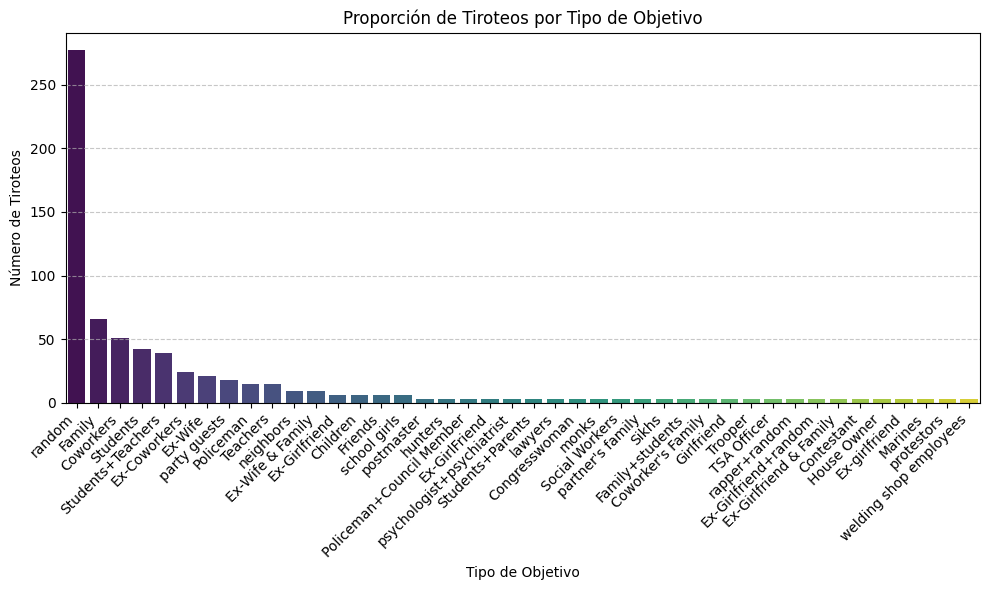

In [ ]:
# Proporción de tiroteos por tipo de objetivo
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Target', order=df['Target'].value_counts().index, palette='viridis')
plt.title('Proporción de Tiroteos por Tipo de Objetivo')
plt.xlabel('Tipo de Objetivo')
plt.ylabel('Número de Tiroteos')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Número de Víctimas vs. Problemas de Salud Mental del Perpetrador

Este gráfico de caja compara el número total de víctimas en tiroteos entre perpetradores con y sin problemas de salud mental. Muestra cómo varía la cantidad de víctimas en función de si el perpetrador tenía problemas de salud mental reportados, ayudando a entender si existe una diferencia significativa en la severidad de los incidentes.

<ipython-input-23-97ecb4553347>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Mental Health Issues', y='Total victims', data=df_filtered, palette='Set2')


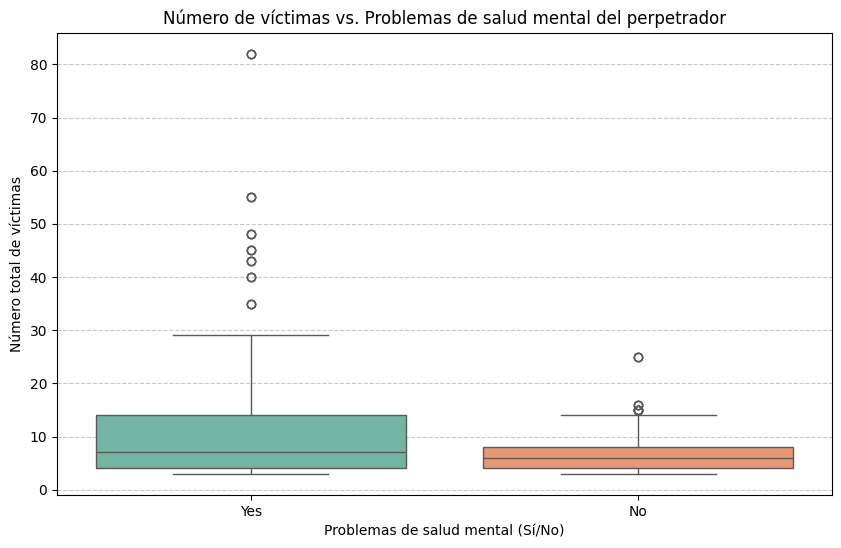

In [ ]:
import seaborn as sns


# Filtrar los datos para incluir solo 'Yes' y 'No' en 'Mental Health Issues'
df_filtered = df[df['Mental Health Issues'].isin(['Yes', 'No'])]

# Crear el gráfico de caja
plt.figure(figsize=(10, 6))
sns.boxplot(x='Mental Health Issues', y='Total victims', data=df_filtered, palette='Set2')
plt.title('Número de víctimas vs. Problemas de salud mental del perpetrador')
plt.xlabel('Problemas de salud mental (Sí/No)')
plt.ylabel('Número total de víctimas')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Distribución de Víctimas Totales por Tiroteo

Este gráfico de caja muestra la distribución del número total de víctimas (fatales e heridas) en los tiroteos. Permite observar la variabilidad y la dispersión en el número de víctimas por incidente, revelando si hay eventos con un número inusualmente alto o bajo de víctimas.

<ipython-input-24-718afc0816f9>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[:, 'Total Victims'] = df['Fatalities'].fillna(0) + df['Injured'].fillna(0)


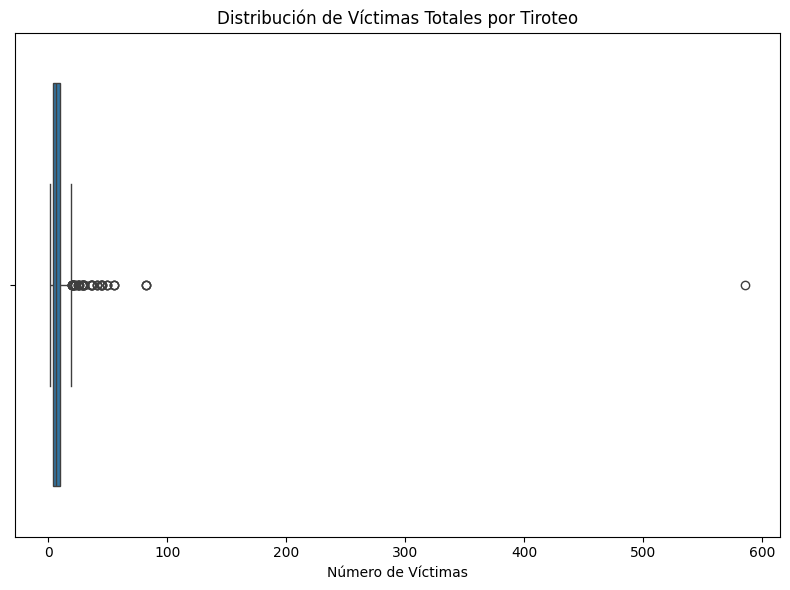

<ipython-input-24-718afc0816f9>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['Total Victims'], inplace=True)


In [ ]:
import seaborn as sns


# Calcular el número total de víctimas por tiroteo de manera segura
df.loc[:, 'Total Victims'] = df['Fatalities'].fillna(0) + df['Injured'].fillna(0)

# Graficar la distribución de víctimas totales por tiroteo
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['Total Victims'])
plt.title('Distribución de Víctimas Totales por Tiroteo')
plt.xlabel('Número de Víctimas')
plt.tight_layout()
plt.show()
df.drop(columns=['Total Victims'], inplace=True)

## Proporción de Tiroteos con Problemas de Salud Mental Reportados

Este gráfico de pastel ilustra la proporción de tiroteos en los que se reportaron problemas de salud mental en comparación con los que no tienen tales reportes. Muestra el porcentaje de tiroteos con y sin problemas de salud mental, proporcionando una visión clara de cuán común es esta característica entre los perpetradores.

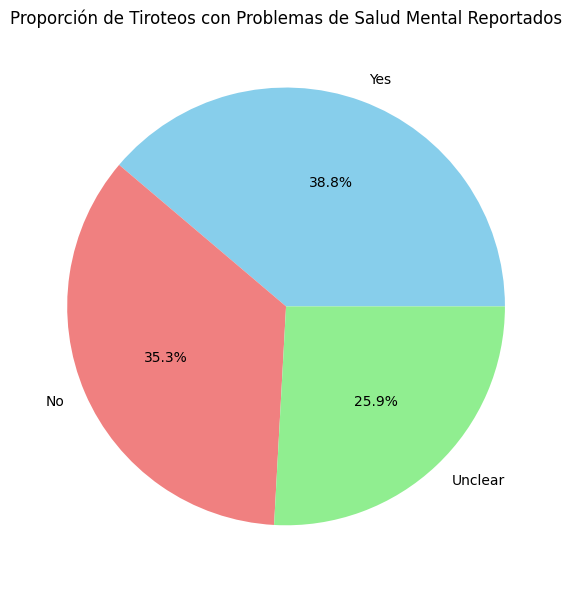

In [ ]:
# Contar el número de tiroteos con problemas de salud mental reportados
salud_mental_counts = df['Mental Health Issues'].value_counts()

# Graficar la proporción de tiroteos con problemas de salud mental reportados en un gráfico de pastel
plt.figure(figsize=(6, 6))
plt.pie(salud_mental_counts, labels=salud_mental_counts.index, autopct='%1.1f%%', colors=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Proporción de Tiroteos con Problemas de Salud Mental Reportados')
plt.tight_layout()
plt.show()


## Frecuencia de Tiroteos por Género

Este gráfico de barras muestra la cantidad de tiroteos según el género de los perpetradores. Permite ver la distribución de incidentes entre diferentes géneros, facilitando la comparación de la frecuencia de tiroteos cometidos por cada grupo.

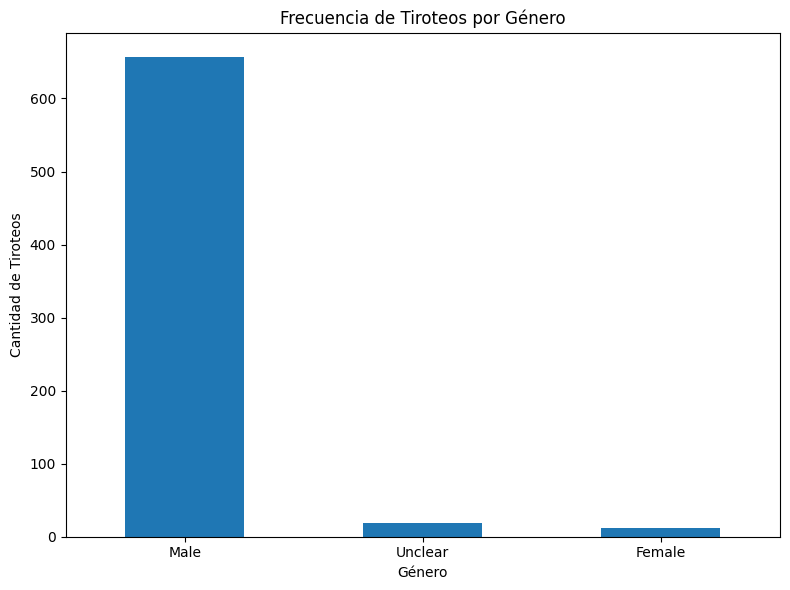

In [ ]:
# Contar el número de tiroteos por género
genero_counts = df['Gender'].value_counts()

# Graficar la frecuencia de tiroteos por género
plt.figure(figsize=(8, 6))
genero_counts.plot(kind='bar')
plt.title('Frecuencia de Tiroteos por Género')
plt.xlabel('Género')
plt.ylabel('Cantidad de Tiroteos')
plt.xticks(rotation=0)  # No es necesario rotar las etiquetas en este caso
plt.tight_layout()
plt.show()


## Grafica de edad promedio vs año

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df_filtered = df[df['Age'] != 0].copy()
df_filtered.loc[:, 'Year'] = df_filtered['Date'].dt.year
edad_promedio = df_filtered.groupby('Year')['Age'].mean().reset_index()
edad_promedio.columns = ['Año', 'Edad Promedio']
edad_promedio

<ipython-input-27-7d3b97c72c63>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')


,Año,Edad Promedio
0,1966,21.500000
1,1974,15.500000
2,1976,27.500000
3,1979,17.500000
4,1982,34.000000
5,1983,39.000000
6,1984,36.000000
7,1985,22.000000
8,1986,29.000000
9,1987,59.000000


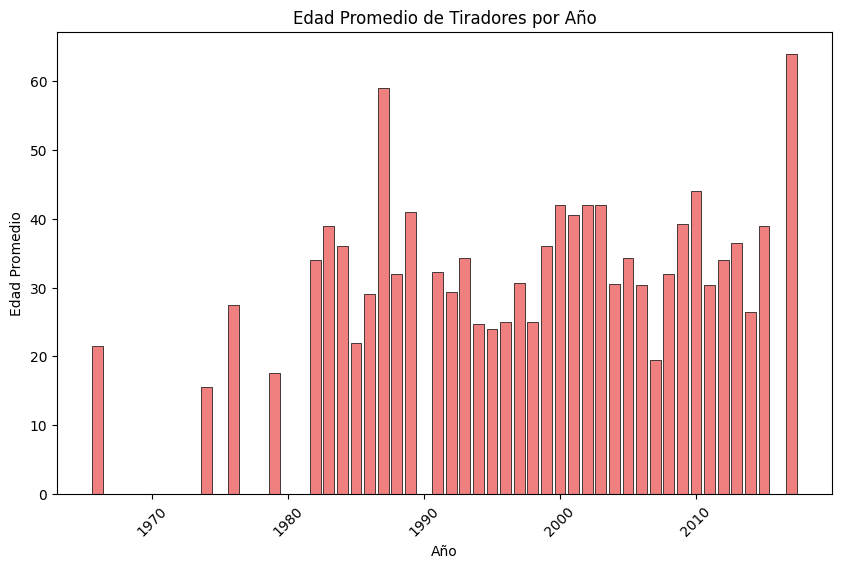

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(edad_promedio['Año'], edad_promedio['Edad Promedio'], color='lightcoral', edgecolor='black', linewidth=0.5)
plt.xlabel('Año')
plt.ylabel('Edad Promedio')
plt.title('Edad Promedio de Tiradores por Año')
plt.xticks(rotation=45)
plt.show()

In [ ]:
import folium
from folium.plugins import HeatMap
from google.colab import files

# Crear un mapa centrado en una ubicación promedio
m = folium.Map(location=[df['Latitude'].mean(), df['Longitude'].mean()], zoom_start=10)

# Añadir un mapa de calor
heat_data = [[row['Latitude'], row['Longitude']] for index, row in df.iterrows()]
HeatMap(heat_data).add_to(m)

# Guardar el mapa en un archivo HTML
m.save('heatmap.html')
files.download('heatmap.html')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>